## Pubchem database collection

In [27]:
import pandas as pd
from pathlib import Path

files = sorted(Path("Raw_data_PubChem/Raw_data").glob("*.csv")) # tạo danh sách các file CSV trong thư mục "Raw_data_PubChem/Raw_data" và sắp xếp chúng theo tên

dfs = [] # tạo danh sách rỗng để lưu trữ các DataFrame từ các file CSV
for f in files:
    try:
        dfs.append(pd.read_csv(f).assign(source_file=f.name))
    except (pd.errors.EmptyDataError, UnicodeDecodeError) as e:
        print(f"Skipped {f.name}: {e}")

df = pd.concat(dfs, ignore_index=True)

# Kiểm tra: các file có cùng cột không?
print("Số cột khác nhau giữa các file:", len({tuple(d.columns) for d in dfs}) )

df.info()

Số cột khác nhau giữa các file: 16
<class 'pandas.DataFrame'>
RangeIndex: 32384 entries, 0 to 32383
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PUBCHEM_RESULT_TAG             32384 non-null  str    
 1   PUBCHEM_SID                    24548 non-null  float64
 2   PUBCHEM_CID                    24526 non-null  float64
 3   PUBCHEM_EXT_DATASOURCE_SMILES  24526 non-null  str    
 4   PUBCHEM_ACTIVITY_OUTCOME       24548 non-null  str    
 5   PUBCHEM_ACTIVITY_SCORE         0 non-null      float64
 6   PUBCHEM_ACTIVITY_URL           0 non-null      float64
 7   PUBCHEM_ASSAYDATA_COMMENT      2144 non-null   object 
 8   Standard Type                  31556 non-null  str    
 9   Activity Comment               4347 non-null   str    
 10  source_file                    32384 non-null  str    
 11  Standard Relation              27749 non-null  str    
 12  Standard Value        

In [28]:
print(df[['Standard Value', 'Standard Units', 'Standard Relation', 'Standard Type']].head)


<bound method NDFrame.head of       Standard Value Standard Units Standard Relation  \
0                NaN            NaN               NaN   
1                NaN            NaN               NaN   
2                NaN            NaN               NaN   
3                NaN            NaN               NaN   
4                NaN            NaN               NaN   
...              ...            ...               ...   
32379           6.25        ug.mL-1                 =   
32380            0.1        ug.mL-1                 =   
32381            0.2        ug.mL-1                 =   
32382           0.39        ug.mL-1                 =   
32383           0.78        ug.mL-1                 =   

                                           Standard Type  
0                                                 STRING  
1      Standardized activity type (e.g. IC50 rather t...  
2                                               Activity  
3                                                

In [29]:
df=df.dropna(subset=['Standard Value', 'Standard Units', 'Standard Relation', 'PUBCHEM_EXT_DATASOURCE_SMILES'], how='any')

In [30]:
print(df['Standard Type'].value_counts(False))

Standard Type
MIC         17110
IC50          771
MBC           766
IZ            641
Activity      347
            ...  
deltaH          1
deltaS          1
MTD             1
MHC             1
C0              1
Name: count, Length: 65, dtype: int64


In [31]:
df = df[df['Standard Type'].isin(['MIC', 'IC50'])]  # Lọc dữ liệu chỉ giữ lại các hàng có 'Standard Type' là 'MIC' hoặc 'IC50'
print(df['Standard Type'].value_counts())

Standard Type
MIC     17110
IC50      771
Name: count, dtype: int64


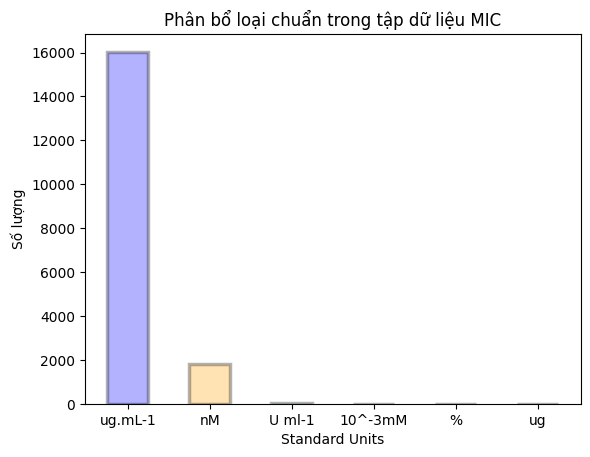

In [32]:
# Vizualize the distribution of 'Standard Units' in the dataset
import matplotlib.pyplot as plt

df['Standard Units'].value_counts() # Đếm số lượng các giá trị duy nhất trong cột 'Standard Units'
plt.bar(df['Standard Units'].value_counts().index, # lấy các giá trị duy nhất của 'Standard Units' làm nhãn trên trục x
        df['Standard Units'].value_counts().values, # lấy số lượng tương ứng của mỗi giá trị làm chiều cao của cột
        color=['blue', 'orange', 'green', 'red', 'purple'],  # màu sắc cho mỗi cột
        width=0.5, # độ rộng của cột
        edgecolor='black', # màu viền của cột
        alpha=0.3, # độ trong suốt của cột (0-1)
        align='center',
        linewidth=2.5) # độ dày của viền cột
    


plt.title('Phân bổ loại chuẩn trong tập dữ liệu MIC')
plt.ylabel('Số lượng')
plt.xlabel('Standard Units')
plt.xticks(rotation=0);

In [46]:
df["Standard Value"] = pd.to_numeric(df["Standard Value"], errors="coerce")
print(df['Standard Value'].dtype)

float64


In [47]:
# Tính khối lượng phân tử chính xác sử dụng RDKit
from rdkit import Chem
from rdkit.Chem import Descriptors

def calculate_mw(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol:
            # Tính toán khối lượng phân tử chính xác từ cấu trúc
            return Descriptors.MolWt(mol)
    except:
        return None
    return None

# Áp dụng tính MW cho DataFrame
df['MW_RDKit'] = df['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(calculate_mw)
df[['PUBCHEM_EXT_DATASOURCE_SMILES', 'MW_RDKit', 'Standard Value']].head(10)

,PUBCHEM_EXT_DATASOURCE_SMILES,MW_RDKit,Standard Value
0,C1COCCN1C(=O)CN2C3=C(C=C(C=C3)Br)C=C2C4=CC5=C(...,517.221,6.0
1,C1=CC2=C(C=C1Br)NC(=C2)C3=CC4=C(N3CCO)C=CC(=C4)Br,434.131,1.3
2,C1=CC2=C(C=C1Br)C=C(N2)C3=NC4=C(S3)C=C(C=C4)Br,408.118,4.1
3,CN1C(=CC2=C1C=C(C=C2)Br)C#CC3=CC4=C(N3)C=C(C=C...,428.127,13.7
4,C1=CC=C2C(=C1)C=C(N2)C3=CC=C(C=C3)C4=CC5=C(N4)...,387.280,5.6
5,C1=CC2=C(C=C1Br)C=C(N2)C3=CC4=CC(=C(C=C4N3)Br)Br,468.974,1.6
6,C1=CC2=C(C=C1Br)NC(=C2)C3=CC4=C(N3CC(=O)O)C=CC...,448.114,11.1
7,C1=CC2=C(C=C1Br)NC(=C2)C#CC3=CC4=C(N3)C=CC(=C4)Br,414.100,4.7
8,COC1=C(C=CC(=C1)C2=CC3=CC=CC=C3N2)C4=CC5=C(N4)...,417.306,2.1
9,C1=CC=C2C(=C1)N=C(S2)C3=CC4=C(N3)C=C(C=C4)Br,329.222,151.7


In [48]:
import os
import pandas as pd
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

chooser = rdMolStandardize.LargestFragmentChooser()   # remove salts/solvents
uncharger = rdMolStandardize.Uncharger()              # neutralize charges

def standardize(smiles): # Using RDKit to standardize SMILES
    if not isinstance(smiles, str): # If the input is not a string, return None
        return None
    mol = Chem.MolFromSmiles(smiles) # Convert SMILES to RDKit Mol object
    if mol is None:
        return None
    mol = uncharger.uncharge(chooser.choose(mol)) # Remove salts/solvents and neutralize charges
    return Chem.MolToSmiles(mol)  # add isomericSmiles=False to drop stereo



In [49]:
# Analyze and process the input files
import pandas as pd

def process(df): 
    n_rows = len(df)
    df = df.copy()

    df["Canonical_SMILES"] = df["PUBCHEM_EXT_DATASOURCE_SMILES"].map(standardize)
    df = df.dropna(subset=["Canonical_SMILES"]).copy()
    n_invalid = n_rows - len(df)

        
     # Mark ALL rows whose structure appears more than once
    dup_mask = df.duplicated("Canonical_SMILES", keep=False)
    n_dup_compounds = df.loc[dup_mask, "Canonical_SMILES"].nunique()

    removed, kept = df[dup_mask], df[~dup_mask]

    print(f"rows={n_rows}, invalid={n_invalid}, "
          f"duplicated compounds={removed['Canonical_SMILES'].nunique()} "
          f"({len(removed)} rows removed), kept={len(kept)}")
    return kept, removed
df_cleaned, df_removed = process(df)

[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00

rows=583, invalid=0, duplicated compounds=0 (0 rows removed), kept=583


[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Fragment: NC[C@H]1O[C@@H](O[C@@H](Cn2cc(CCCCCCCCCCOc3ccc(C(=O)c4ccccc4)cc3)nn2)[C@H]2O[C@@H](n3ccc(=O)[nH]c3=O)[C@H](O)[C@@H]2O)[C@H](O)[C@@H]1O
[11:00:12] New largest fragment: NC[C@H]1O[C@@H](O[C@@H](Cn2cc(CCCCCCCCCCOc3ccc(C(=O)c4ccccc4)cc3)nn2)[C@H]2O[C@@H](n3ccc(=O)[nH]c3=O)[C@H](O)[C@@H]2O)[C@H](O)[C@@H]1O (109)
[11:00:12] Fragment: O=C(O)C(F)(F)F
[11:00:12] Running Uncharger
[11:00:12] Running LargestFragmentChooser
[11:00:12] Fragment: NC[C@H]1O[C@@H](O[C@@H](Cc2cn(CCCCCCCCCCOc3ccc(C(=O)c4ccccc4)cc3)nn2)[C@H]2O[C@@H](n3ccc(=O)[nH]c3=O)[C@H](O)[C@@H]2O)[C@H](O)[C@@H]1O
[11:00:12] New largest fragment: NC[C@H]1O[C@@H](O[C@@H](Cc2cn(CCCCCCCCCCOc3ccc(C(=O)c4ccccc4)cc3)nn2)[C@H]2O[C@@H](n3ccc(=O)[nH]c3=O)[C@H](O)[C@@H]2O)[C@H](O)[C@@H]1O (109)
[11:00:12] Fragment: O=C(O)C(F)(F)F
[11:00:12] Ru

In [50]:
df_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PUBCHEM_RESULT_TAG             583 non-null    str    
 1   PUBCHEM_SID                    583 non-null    float64
 2   PUBCHEM_CID                    583 non-null    float64
 3   PUBCHEM_EXT_DATASOURCE_SMILES  583 non-null    str    
 4   PUBCHEM_ACTIVITY_OUTCOME       583 non-null    str    
 5   PUBCHEM_ACTIVITY_SCORE         0 non-null      float64
 6   PUBCHEM_ACTIVITY_URL           0 non-null      float64
 7   PUBCHEM_ASSAYDATA_COMMENT      0 non-null      object 
 8   Standard Type                  583 non-null    str    
 9   Activity Comment               0 non-null      str    
 10  source_file                    583 non-null    str    
 11  Standard Relation              583 non-null    str    
 12  Standard Value                 583 non-null    float64
 13  S

In [37]:
smi_col = "Canonical_SMILES"
raw = df_removed.copy()
raw["canon"] = raw[smi_col].map(standardize)
valid = raw.dropna(subset=["canon"])

print("rows:", len(raw))
print("unique raw SMILES:", raw[smi_col].nunique())
print("valid rows:", len(valid))
print("unique canonical:", valid["canon"].nunique())

counts = valid["canon"].value_counts()
print(counts.head(10))
print("compounds appearing > 1 time:", (counts > 1).sum())

[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54:57] Running LargestFragmentChooser
[10:54:57] Running Uncharger
[10:54

rows: 17298
unique raw SMILES: 1830
valid rows: 17298
unique canonical: 1830
canon
CN[C@H](CC(C)C)C(=O)N[C@H]1C(=O)N[C@@H](CC(N)=O)C(=O)N[C@H]2C(=O)N[C@H]3C(=O)N[C@H](C(=O)N[C@H](C(=O)O)c4cc(O)cc(O)c4-c4cc3ccc4O)[C@H](O)c3ccc(c(Cl)c3)Oc3cc2cc(c3O[C@@H]2O[C@H](CO)[C@@H](O)[C@H](O)[C@H]2O[C@H]2C[C@](C)(N)[C@H](O)[C@H](C)O2)Oc2ccc(cc2Cl)[C@H]1O    513
CCCCCCCCCNc1ccc(F)c(C(N)=O)c1F                                                                                                                                                                                                                                          175
O=C(O)c1cn(C2CC2)c2cc(N3CCNCC3)c(F)cc2c1=O                                                                                                                                                                                                                              144
O=C1c2cccnc2C(=O)c2c1c(C(=O)OCCCCCN1CCOCC1)c1ccc(Br)cn21                                                         

[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55:08] Running LargestFragmentChooser
[10:55:08] Running Uncharger
[10:55

In [51]:
df = df_cleaned.dropna(subset=["Standard Value", "Standard Units"]).reset_index(drop=True)

In [52]:
df['Standard Relation'].value_counts()

Standard Relation
=     435
>     131
<      12
<=      4
>=      1
Name: count, dtype: int64

In [53]:
def convert_to_nM(row):
    val = row['Standard Value']
    unit = str(row['Standard Units']).strip().lower().replace('µ', 'u')
    mw = row['MW_RDKit']

    if pd.isna(val) or val <= 0:
        return None

    # 1. Picomolar group (divide by 1000)
    if unit in ['pm', 'p m', 'picomolar', '10^-12m']:
        return val / 1000

    # 2. Nanomolar group (keep the same)
    if unit in ['nm', 'n m', 'nanomolar', '10^-9m']:
        return val

    # 3. Micromolar group (multiply by 1000)
    if unit in ['um', 'u m', 'micromolar', '10^-6m', '10^-3mm']:
        return val * 1000

    # 4. Millimolar group (multiply by 1,000,000)
    if unit in ['mm', 'm m', 'millimolar', '10^-3m']:
        return val * 1_000_000

    # 5. Molar group (multiply by 1,000,000,000)
    if unit in ['m', 'molar']:
        return val * 1_000_000_000

    # 6. Mass group (needs MW): ug/mL = mg/L, so nM = (val * 1e6) / MW
    mass_units = ['ug/ml', 'ug.ml-1', 'ug ml-1', 'ug/m l', 'mg/l', 'mg.l-1']
    if unit in mass_units:
        if pd.isna(mw) or mw <= 0:
            return None
        return (val * 1_000_000) / mw

    return None   # unknown unit

In [ ]:
# 1. Back up the original 'Standard Value' to validate the conversion
if 'Original Value' not in df.columns:
    df['Original Value'] = df['Standard Value']
    df['Original Units'] = df['Standard Units']

# 2. Convert the values and set the unit only where conversion worked
df['Standard Value'] = df.apply(convert_to_nM, axis=1)
df['Standard Units'] = df['Standard Value'].notna().map({True: 'nM', False: None})

# 3. Check which units were converted and then drop those rows
print(df.loc[df['Standard Value'].isna(), 'Original Value'].value_counts())
df = df.dropna(subset=['Standard Value']).reset_index(drop=True)

#4. Final check
assert (df['Standard Units'] == 'nM').all(), "Not all values are in nM after conversion!"
print(f"done | row: {len(df)}")


Series([], Name: count, dtype: int64)
done | row: 581


In [56]:
keep = ["PUBCHEM_CID", "Canonical_SMILES", "PUBCHEM_EXT_DATASOURCE_SMILES",
        "Standard Type", "Standard Relation", "Standard Value", "Standard Units",
        "Data Validity Comment"]

df = df[keep].copy()

In [57]:
df.to_csv("Processed_data_PubChem/Cleaned_data_PubChem.csv", index=False)

In [58]:
df.to_csv("Processed_data_PubChem/Filtered_data_PubChem.csv", index=False)
print(pd.read_csv("Processed_data_PubChem/Filtered_data_PubChem.csv").info())

<class 'pandas.DataFrame'>
RangeIndex: 581 entries, 0 to 580
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PUBCHEM_CID                    581 non-null    float64
 1   Canonical_SMILES               581 non-null    str    
 2   PUBCHEM_EXT_DATASOURCE_SMILES  581 non-null    str    
 3   Standard Type                  581 non-null    str    
 4   Standard Relation              581 non-null    str    
 5   Standard Value                 581 non-null    float64
 6   Standard Units                 581 non-null    str    
 7   Data Validity Comment          5 non-null      str    
dtypes: float64(2), str(6)
memory usage: 113.7 KB
None


In [60]:
print(pd.read_csv("Processed_data_PubChem/Filtered_data_PubChem.csv").head())

   PUBCHEM_CID                                   Canonical_SMILES  \
0   76310467.0  O=C(Cn1c(-c2cc3ccc(Br)cc3[nH]2)cc2cc(Br)ccc21)...   
1   76310468.0        OCCn1c(-c2cc3ccc(Br)cc3[nH]2)cc2cc(Br)ccc21   
2   76310469.0             Brc1ccc2[nH]c(-c3nc4ccc(Br)cc4s3)cc2c1   
3   76310470.0        Cn1c(C#Cc2cc3ccc(Br)cc3[nH]2)cc2ccc(Br)cc21   
4   76310471.0   Brc1ccc2cc(-c3ccc(-c4cc5ccccc5[nH]4)cc3)[nH]c2c1   

                       PUBCHEM_EXT_DATASOURCE_SMILES Standard Type  \
0  C1COCCN1C(=O)CN2C3=C(C=C(C=C3)Br)C=C2C4=CC5=C(...          IC50   
1  C1=CC2=C(C=C1Br)NC(=C2)C3=CC4=C(N3CCO)C=CC(=C4)Br          IC50   
2     C1=CC2=C(C=C1Br)C=C(N2)C3=NC4=C(S3)C=C(C=C4)Br          IC50   
3  CN1C(=CC2=C1C=C(C=C2)Br)C#CC3=CC4=C(N3)C=C(C=C...          IC50   
4  C1=CC=C2C(=C1)C=C(N2)C3=CC=C(C=C3)C4=CC5=C(N4)...          IC50   

  Standard Relation  Standard Value Standard Units Data Validity Comment  
0                 =             6.0             nM                   NaN  
1             